# Flows (appendix)

Who is recommended, by prompt variable or model characteristic. 

Inputs: `metrics/<variant>/flows/` (run_metrics_pipeline.sh -s flows). 

Plots: `plots/<variant>/flows_*`.

In [1]:
# Setup: code/libs importable, library changes re-imported automatically
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

from metrics import flows
from utils import analysis_config
from utils import constants as cons
from viz import constants as viscons
from viz import flow_plots
from viz.figures import save_figure
from viz.style import apply_style

apply_style()

'DejaVu Serif'

In [2]:
# Parameters
SMOKE = False                                   # True: smoke-test outputs in tmp/smoke/, False: results/
VARIANT = 'main'                               # analysis variant: config/variants/<VARIANT>.yaml (main: config/analysis.yaml)
SAVE = True                                    # the paper figures: drift heatmap, field / subfield / location -> gender, ethnicity
FORMATS = ['pdf']                              # e.g. ['png', 'pdf']
DRIFT_INCLUDE = ['MX']                         # countries with their own column in the drift heatmap (besides the top ones)
PAPER_SOURCES = ['field', 'subfield', 'location']   # prompt variables of the paper flow figures
INCLUDE_UNKNOWN = None                         # None: as the config (social.include_unknown) | True | False
NCOLS = viscons.FLOW_GRID_NCOLS                # panels per row: 3 (2 x 3) | 6 (1 x 6)
TARGETS = flows.TARGETS                        # person attributes: gender, ethnicity, country, author_seniority, productivity, influence
SOURCES = viscons.FLOW_SOURCES                 # prompt variables / model characteristics (target-fixed figures)
RESULTS_DIR = PROJECT / 'tmp' / 'smoke' if SMOKE else Path(cons.DEFAULT_RESULTS_DIR)
from utils import analysis_config
V = analysis_config.notebook_variant(VARIANT, SMOKE)  # folders + config of the variant (configure_variant.py)
METRICS_DIR = Path(V['metrics_dir'])
PLOTS_DIR = Path(V['plots_dir'])
CONFIG = Path(V['config'])
analysis_config.require_late_reviewed(CONFIG)  # gender labels, valid tags: reviewed (late settings)
config = analysis_config.load(CONFIG)
GENDER_LABELS, BIN_LABELS = config['gender']['labels'], config['prominence']['bin_labels']
INCLUDE_UNKNOWN = config['social']['include_unknown'] if INCLUDE_UNKNOWN is None else INCLUDE_UNKNOWN

In [3]:
# Data: one row per (valid response, factual person) = a MENTION (n in the plots counts mentions: a person recommended
# in several responses counts each time); with the prompt variables, model characteristics and GT attributes
people = flow_plots.with_model_columns(flows.load_people(METRICS_DIR))
print(f"{len(people):,} rows | {people['author_id'].nunique():,} people | {people[cons.COL_MODEL].nunique()} models | unknown: "
      + ', '.join(f"{t} {flows.unknown_share(people, t):.1%}" for t in ['gender', 'ethnicity', 'country']))

1,281,796 rows | 274,797 people | 43 models | unknown: gender 1.6%, ethnicity 1.8%, country 22.4%


## Country Drift
prompted location → country of the recommended people

In [4]:
# Share from the prompt's country vs the same share when other locations are prompted (lift = ratio); 95% CI over models
drift = flows.drift(people)
drift.round(3)

,location,country,n,share,baseline,lift,share_ci_low,share_ci_high,baseline_ci_low,baseline_ci_high,lift_ci_low,lift_ci_high,n_models
0,Canada,CA,224897,0.204,0.015,13.686,0.141,0.270,0.013,0.017,9.196,18.866,43
1,Ecuador,EC,240510,0.058,0.001,51.658,0.045,0.081,0.001,0.002,28.465,99.697,43
2,Germany,DE,197377,0.605,0.017,36.588,0.556,0.649,0.015,0.019,30.246,42.919,43
3,Japan,JP,201991,0.834,0.002,344.477,0.807,0.854,0.002,0.003,294.865,399.058,43
4,South Africa,ZA,130517,0.230,0.001,215.696,0.144,0.328,0.001,0.001,122.454,348.774,43


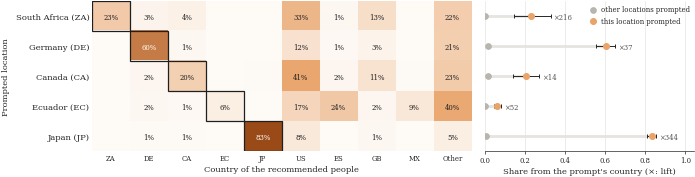

In [5]:
# Heatmap of the country shares per prompted location (own country outlined) and the drift per location
fig = flow_plots.plot_drift(people, drift, include=DRIFT_INCLUDE)
if SAVE:
    save_figure(fig, 'flows_drift_location', PLOTS_DIR, FORMATS)

## Demographics composition
prompted field/subfield/country → gender/ethnicity recommended people

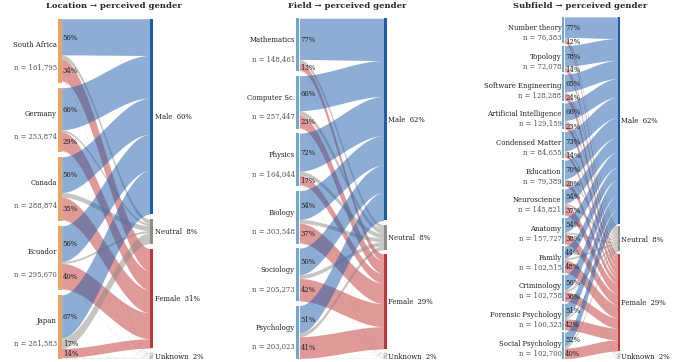

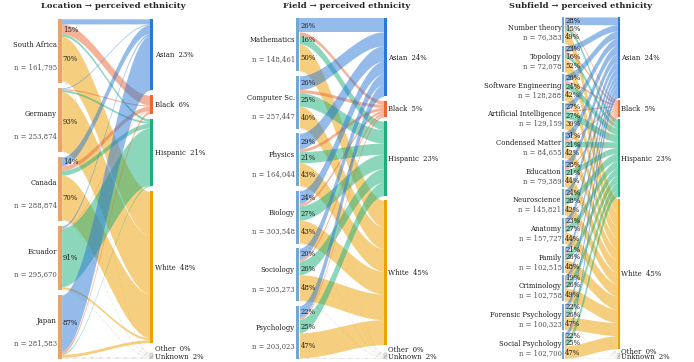

In [6]:
# Sources: prompt variables (location, field, subfield)
# targets: gender, ethnicity
for r in ['gender','ethnicity']:
    PAIRS = [(p,r) for p in ['location','field','subfield']]
    fig = flow_plots.plot_flows(people, PAIRS, INCLUDE_UNKNOWN, GENDER_LABELS, BIN_LABELS)
    if SAVE:
        save_figure(fig, f'flows_to_{r}', PLOTS_DIR, FORMATS)

# All flows

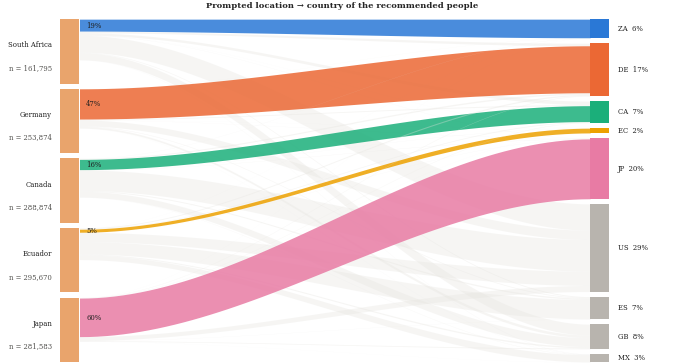

In [7]:
# The drift as a flow: each location's band to its own country in colour, the others faded
fig = flow_plots.plot_drift_flow(people, include_unknown=INCLUDE_UNKNOWN)

## Flows: one prompt variable → the people's attributes

Bands: within-value shares; right: mean composition. Factual people = matched at the author level (name + requested field + seniority), so their seniority mostly follows the requested one.

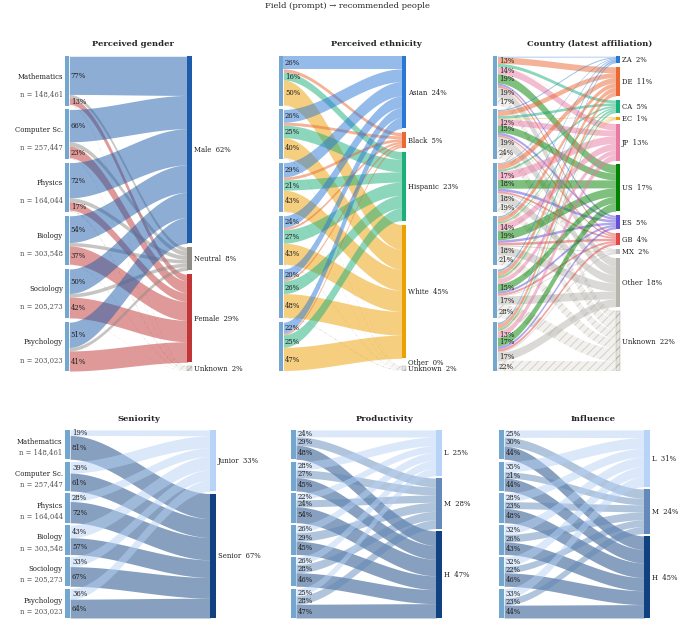

In [8]:
fig = flow_plots.plot_flow_grid(people, source='field', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

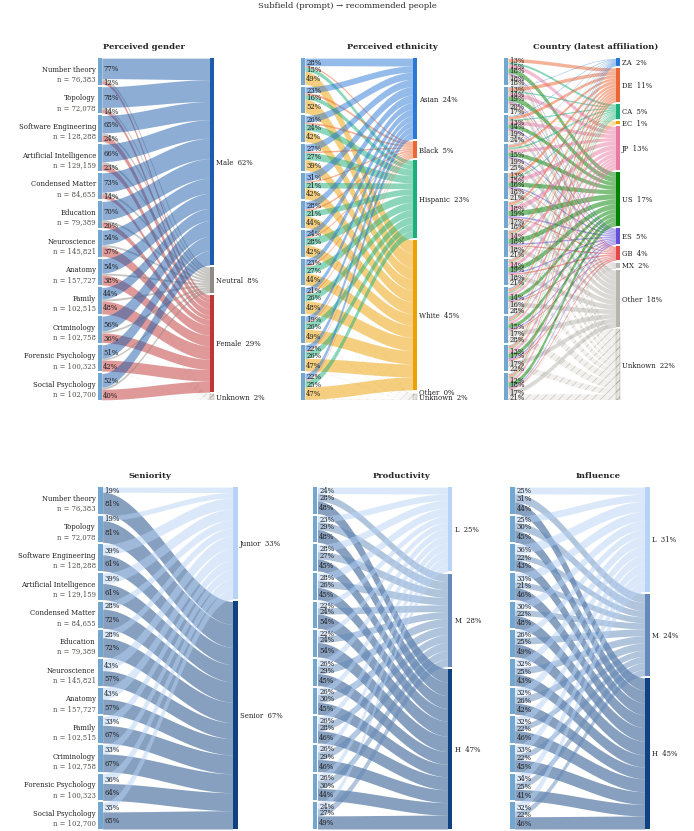

In [9]:
fig = flow_plots.plot_flow_grid(people, source='subfield', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

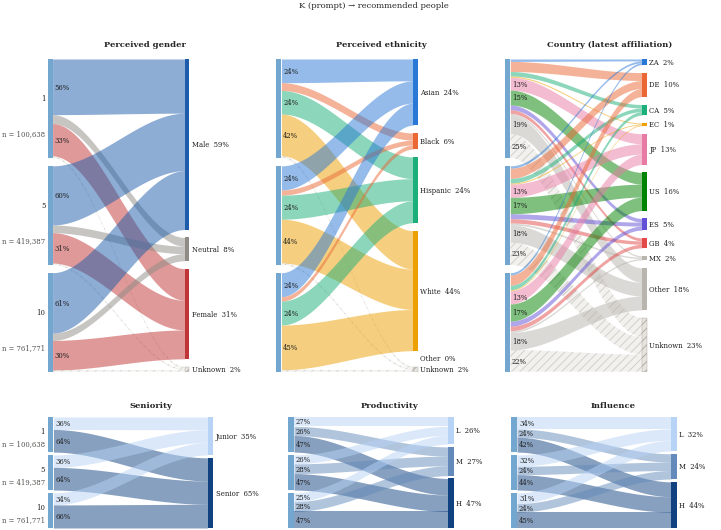

In [10]:
fig = flow_plots.plot_flow_grid(people, source='k', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

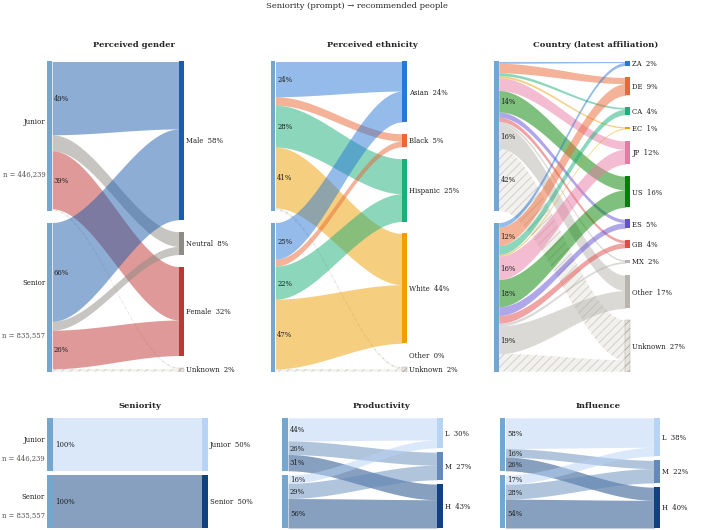

In [11]:
fig = flow_plots.plot_flow_grid(people, source='seniority', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

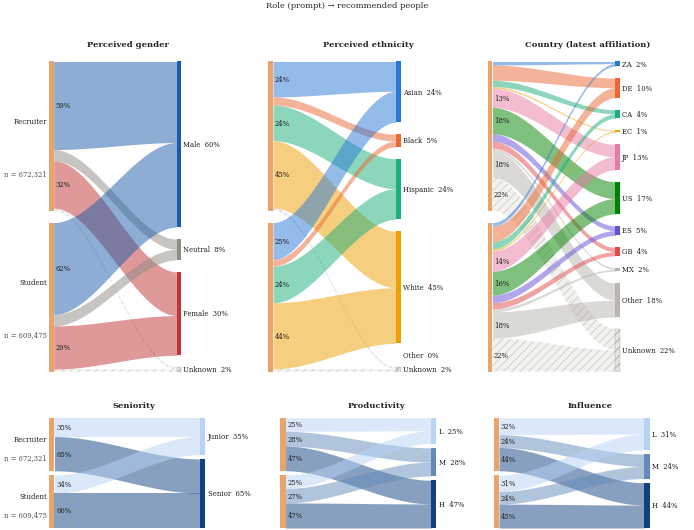

In [12]:
fig = flow_plots.plot_flow_grid(people, source='role', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

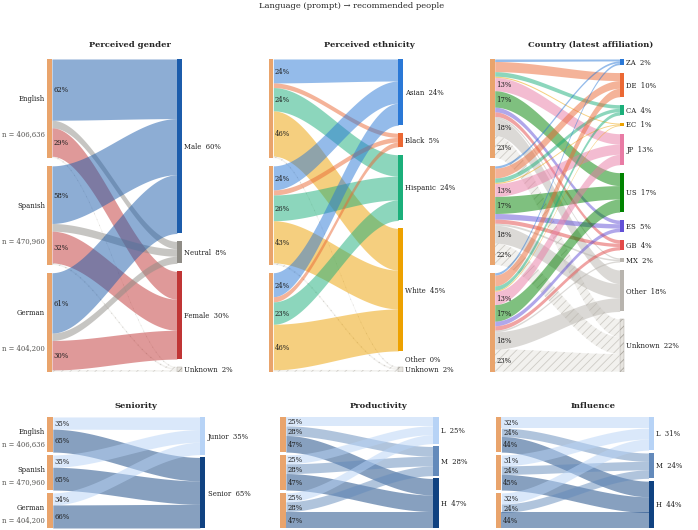

In [13]:
fig = flow_plots.plot_flow_grid(people, source='language', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

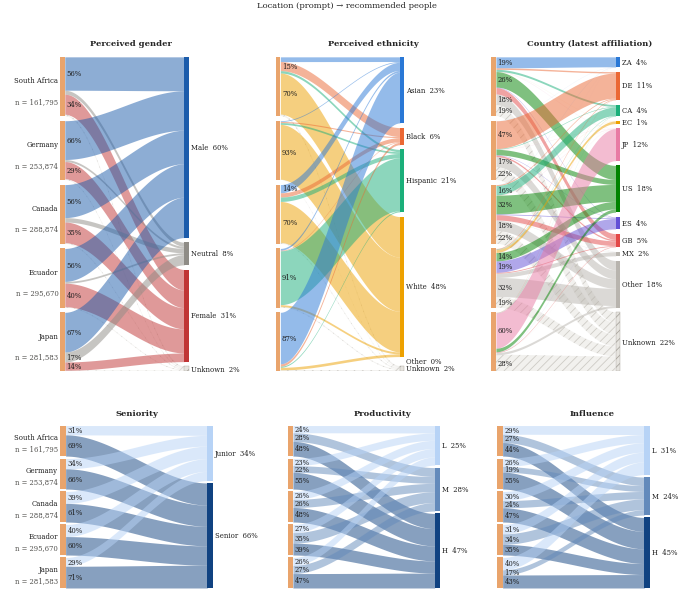

In [14]:
fig = flow_plots.plot_flow_grid(people, source='location', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

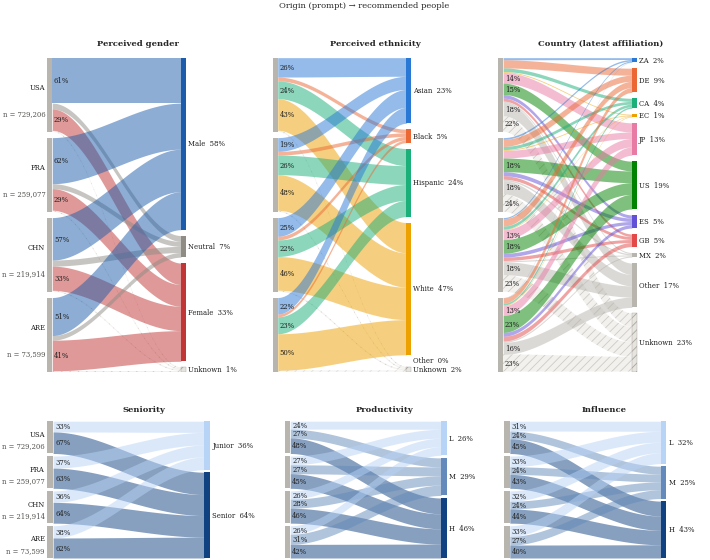

In [15]:
fig = flow_plots.plot_flow_grid(people, source='origin', targets=TARGETS, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                     gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

## Flows: prompt variables → one attribute of the people

Paper figures: the prompt variables of `PAPER_SOURCES` (field, subfield, prompted location); all of them: `SOURCES`.

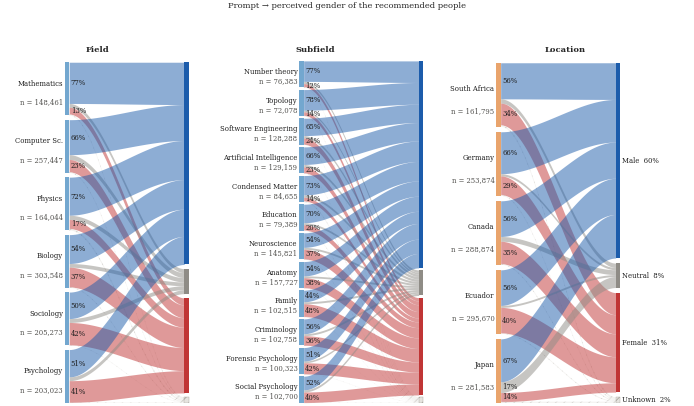

In [16]:
# paper figure: field, subfield and prompted location -> perceived gender
fig = flow_plots.plot_flow_grid(people, target='gender', sources=PAPER_SOURCES, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

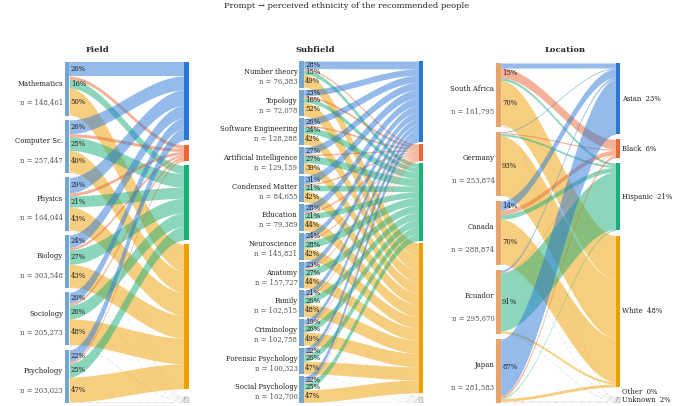

In [17]:
# paper figure: field, subfield and prompted location -> perceived ethnicity
fig = flow_plots.plot_flow_grid(people, target='ethnicity', sources=PAPER_SOURCES, ncols=NCOLS, include_unknown=INCLUDE_UNKNOWN,
                                gender_labels=GENDER_LABELS, bin_labels=BIN_LABELS)

## Any other flow

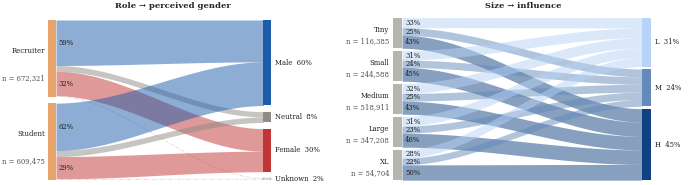

In [18]:
# Sources: prompt variables (language, role, location, k, seniority, field, subfield) or model characteristics
# (access, size, reasoning, origin, family); targets: gender, ethnicity, country, productivity, influence, collaboration
PAIRS = [('role', 'gender'), ('size', 'influence')]
fig = flow_plots.plot_flows(people, PAIRS, INCLUDE_UNKNOWN, GENDER_LABELS, BIN_LABELS)

In [19]:
# Table: shares of the target classes per source value
flows.flow_table(people, 'origin', 'country', INCLUDE_UNKNOWN, top=viscons.FLOW_TOP_COUNTRIES) \
     .pivot(index='source', columns='target', values='share').round(3)

target,CA,DE,ES,GB,JP,MX,US,ZA,other,unknown
source,,,,,,,,,,
ARE,0.024,0.075,0.052,0.065,0.131,0.018,0.229,0.004,0.171,0.232
CHN,0.042,0.099,0.051,0.047,0.132,0.016,0.185,0.017,0.184,0.228
FRA,0.043,0.096,0.055,0.047,0.102,0.021,0.184,0.023,0.191,0.239
USA,0.049,0.110,0.048,0.040,0.144,0.018,0.153,0.029,0.193,0.216
